# Statistics and Robotics
Data is inherently subject to noise.  How we handle this unfortunate side effect of reality is vital in ensuring robots have meaningful data to make inferences with.  We will look at how noise in data can be described, how error occurs in measurements, and what happens when we take multiple measurements at the same time.

In [2]:
# Helper functions and packages
import numpy as np
import matplotlib.pyplot as plt


---
---
## ✏️ Task 1.0 - Noisy Data is _Normal_

The additional noise measured during an observation can (most of the time) be expressed as a normal (Gaussian) distribution.  We better get to grips with the normal distribution, how to sample from one, and how to estimate it's characteristics.


---
Task 1.1

Given a normal distribution $f \sim \mathcal{N}(5.0, 2.0)$, use the _numpy.random.normal()_ function to generate 100 random samples from the distribution.

In [5]:
# Task 1.1

# Set the seed for the random generator - not necessary unless we want results to be reproducible (deterministic)
np.random.seed(seed=123456)
# Draw samples from the random distribution of mean=5.0 and std_dev=sqrt(var)=sqrt(2.0)
mu = 5.0
sigma = np.sqrt(2.0)
normal_samples = np.random.normal( mu, sigma, 100)

---
Task 1.2

Calculate the mean, standard deviation and variance of the _normal_samples_.

In [6]:
# Task 1.2

mean = np.mean(normal_samples)
std_dev = np.std(normal_samples)
var = np.var(normal_samples)

print(f'Mean: {mean}\nStd Dev: {std_dev}\nVariance: {var}')

Mean: 4.698491547012045
Std Dev: 1.410523369224162
Variance: 1.9895761751274816


---
Task 1.3

Comment on the mean and variance of the sample population you drew from the distribution compared to the actual values you would expect.

Answer:the sample mean is  close to the expected mean. while the variance is not large.  this is expected because a larger sample size tends to create an even distribution

Comment on percentage that values are within of expected values 
eg mean is withing 1%, variance withing 6% blablabla

---
Task 1.4 - STRETCH

Run the sampling procedure again but with 1000 samples rather than 100.  Again, comment on the mean and variance estimates of the sample set.

Answer:


In [7]:
# Task 1.4 - STRETCH

# Set the seed for the random generator - not necessary unless we want results to be reproducible (deterministic)
np.random.seed(seed=78910)
# Draw samples from the random distribution of mean=5.0 and std_dev=sqrt(var)=sqrt(2.0)
normal_samples = np.random.normal( mu, sigma, 1000)
mean = np.mean(normal_samples)
std_dev = np.std(normal_samples)
var = np.var(normal_samples)

print(f'Mean: {mean}\nStd Dev: {std_dev}\nVariance: {var}')

Mean: 5.026565503709398
Std Dev: 1.4044623503974887
Variance: 1.972514493684038


---
---
## ✏️ Task 2.0 - Linear Regression
### Stochastic and Systematic Error

---
Task 2.1

Assume a mobile robot is accelerating a constant rate from a standstill ($v=0$).  Given a linear relationship $v_{t} = at + v_{t=0}$, where $v_{t}$ is the linear velocity at time $t$, generate data representing velocity observations made every 0.01 seconds (100 Hz) from a noisy experiment.  You can assume the uncertainty in the time of observation is negligible, and the estimated standard deviation of velocity observations is $0.1$.

The linear acceleration of the robot is limited $2.0\text{ ms}^{-2}$, with a maximum velocity of $1.4\text{ ms}^{-1}$ (therefore it stops accelerating after $0.7\text{ s}$).  Set the random seed to your university ID.

In [8]:
# Task 2.1

# Set the seed for the random generator - not necessary unless we want results to be reproducible (deterministic)
np.random.seed(seed=14431580)

a = 2 # ms^-2
v0 = 0 # Initial velocity
t = np.linspace(0,0.7, 70)  # Times of observations
v = v0 + a * t  # Generate data
v_noisy = v + np.random.normal(0, 0.1, len(t))  # Add noise to "clean" data


---
Task 2.2

Fit a linear regression to the noisy data to estimate the acceleration of the mobile robot.

Answer:

$a = $ 1.99

a: 1.9929080017531042
v0: -0.01597993332464684


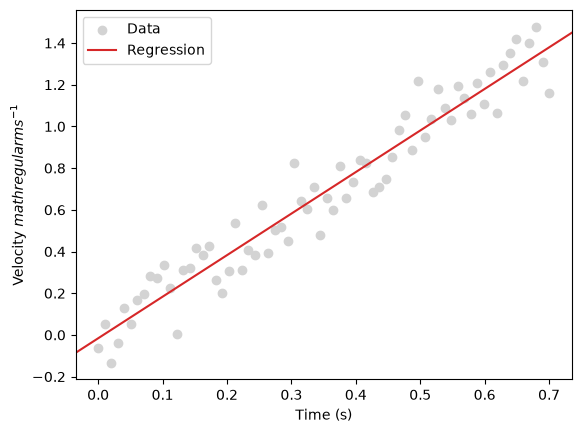

In [ ]:
# Task 2.2

# Use numpy polyfit to fit a 1st order polynomial (linear)
fit = np.polyfit(t, v_noisy, 1,)

# Plot results
fig, ax = plt.subplots(1,1)

# Plot experimental data points
ax.scatter(t, v_noisy, c="lightgrey", label='Data')

# Add linear regression as red line
ax.axline((0, fit[1]), slope=fit[0], color='C3', label='Regression')

ax.set_xlabel('Time (s)')
ax.set_ylabel("Velocity $mathregular{ms^{-1}}$")
ax.legend()

print(f'a: {fit[0]}\nv0: {fit[1]}')

---
Task 2.3

Data from a radar sensor has been provided.  It provides a linear voltage based on distance to an object.  Calibrate the sensor for any systematic error and provide a conversion factor to convert from voltage to distance.

Answer:

$\text{Offset (Volts)}  = $  3.2184484914474907
$\text{Conversion factor} = $ 0.814633335216485

In [10]:
# Task 2.3

# Read in data file whilst skipping the header row
data = np.loadtxt("./radar_data.csv", dtype=float, delimiter=',', skiprows=1)

meters = data[:,0]
volts = data[:,1]

# Perform linear fit on data
fit = np.polyfit(meters, volts, 1)

print(f'Offset: {fit[1]}\nCalibration factor (v/m): {fit[0]}')



Offset: 3.2184484914474907
Calibration factor (v/m): 0.814633335216485


---
Task 2.4 - STRETCH

Repeat the steps taken in Task 2.2, but fix the intercept to $v_{0} = 0$, as this represents a more physically realistic model of the system.  In Task 2.2, this is an example of overfitting, where we do not expect a systematic error when the robot is at standstill.

Answer:

$a = $ 1.95

a: 1.9589116388072463
v0: 0


<>:26: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:26: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
/var/folders/4q/ds_gjm9578x_7xvlj25wdf300000gn/T/ipykernel_54339/372877478.py:26: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  ax.set_ylabel("Velocity $\mathregular{ms^{-1}}$")


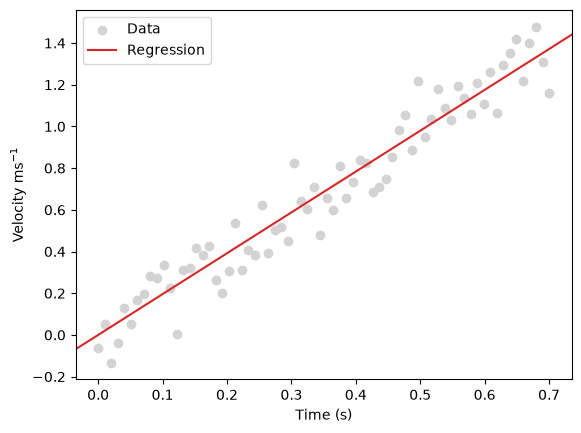

In [13]:
# Task 2.4 - STRETCH
from scipy.optimize import curve_fit

# Function to be fit (can be arbitrary)
# Use y = mx + c
c = 0 # Fix intercept to be 0
#m = 2 #m is the acceleration (slope) of the line

# Inputs are x and m (we will ignore intercept)
# If there was the possibility of a systematic error in c, then we would leave it as a free variable
def fit_func(x, m):
    return (x*m) + c

fit, a_cov = curve_fit(fit_func, t, v_noisy) #, initialGuess)

# Plot results
fig, ax = plt.subplots(1,1)

# Plot experimental data points
ax.scatter(t, v_noisy, c="lightgrey", label='Data')

# Add linear regression as red line
ax.axline((0, c), slope=fit[0], color='C3', label='Regression')

ax.set_xlabel('Time (s)')
ax.set_ylabel("Velocity $\mathregular{ms^{-1}}$")
ax.legend()

a = fit[0]

print(f'a: {a}\nv0: {c}')


---
### Task 2.5 - Stretch

Given a GPS estimate of variance 2.5 m, how many measurements would be required to bring the accuracy within 1 m?

Answer:



In [28]:
# Task 2.5
#new variance is computed as (product/sum) of current & past variance
var_gps = var_gps_current = 2.5
std_dev_gps = np.sqrt(var_gps)

n_obs = 0 # No. of observations required
while std_dev_gps > 1:
    var_gps_new = var_gps_current * var_gps / (var_gps_current + var_gps)
    std_dev_gps = np.sqrt(var_gps_new)
    n_obs += 1

    var_gps_current = var_gps_new


print(f'Number of Obs: {n_obs}\nNew std dev: {std_dev_gps}')

Number of Obs: 2
New std dev: 0.9128709291752769


---
---
## ✏️ Task 3.0 - Multivariate Sensing
Suppose you have two thermocouples mounted on separate motors of a manipulator.  One is on the shoulder, one is attached to a wrist motor (thermocouple 1 and thermocouple 2 respectively).  Under certain conditions the readings from these thermocouples are going to be related to a greater or lesser extent.  There is a covariance between them, i.e. how much does one vary with the other.


---
### Task 3.1

The robot is not operating, so the temperature should be in equilibrium with the room temperature.  Read in data file "thermocouple_data_robot_off.csv", it consists of two columns and header row.  Each row contains observations taken at the same time for both thermocouples.  Calculate the mean and variance for each set of thermocouple readings, then the covariance for both datasets combined.

Note that numpy has a function to calculate the covariance, but ensure "bias=True".

Comment on 1) the mean values of the thermocouples in the covariance matrix 2) the difference between the variances of the two thermocouples 3) the magnitude of the covariance and what you can infer regarding how "coupled" the readings are.

Answer:

In [14]:
# Read in data file whilst skipping the header row
data = np.loadtxt("./thermocouple_data_robot_off.csv", dtype=float, delimiter=',', skiprows=1)

# Separate data into two variables - used as an example
thermocouple_1 = data[:,0]
thermocouple_2 = data[:,1]

# Calculate the means for thermocouples
t_1_mean = np.mean(thermocouple_1)
t_2_mean = np.mean(thermocouple_2)

# Calculate the variances for each thermocouple individually as a different approach
t_1_var = np.var(thermocouple_1)
t_2_var = np.var(thermocouple_2)

# Calculate the covariance
t_covar = np.cov(thermocouple_1, thermocouple_2)[0, 1]

print(f'Mean T1:{t_1_mean}\nMean T2: {t_2_mean}\nVariance T1: {t_1_var}\nVariance T2: {t_2_var}\nCovariance: \n{t_covar}')

Mean T1:18.667520156891342
Mean T2: 20.24628900240633
Variance T1: 1.1255199637525444
Variance T2: 0.8052900287904139
Covariance: 
0.862473003523485


---
### Task 3.2

Repeat the same steps as above, but for "thermocouple_data_robot_on.csv".  In this case, the robot has been running in steady state for 30 minutes, during a pick and place activity moving doughnuts from a conveyor belt into a box.

Again, comment on 1) the mean values of the thermocouples in the covariance matrix 2) the difference between the variances of the two thermocouples 3) the magnitude of the covariance and what you can infer regarding how "coupled" the readings are.

Answer:


In [15]:
# Read in data file whilst skipping the header row
data = np.loadtxt("./thermocouple_data_robot_on.csv", dtype=float, delimiter=',', skiprows=1)

# Separate data into two variables - used as an example
thermocouple_1 = data[:,0]
thermocouple_2 = data[:,1]

# Calculate the means for thermocouples
t_1_mean = np.mean(thermocouple_1)
t_2_mean = np.mean(thermocouple_2)

# Calculate the variances for each thermocouple individually as a different approach
t_1_var = np.var(thermocouple_1)
t_2_var = np.var(thermocouple_2)

# Calculate the covariance
t_covar = np.cov(thermocouple_1, thermocouple_2)[0, 1]

print(f'Mean T1: {t_1_mean}\nMean T2: {t_2_mean}\nVariance T1: {t_1_var}\nVariance T2: {t_2_var}\nCovariance: \n{t_covar}')

Mean T1: 21.19038193294398
Mean T2: 47.88405890133218
Variance T1: 0.9618362938518419
Variance T2: 0.7586226775709204
Covariance: 
0.005603604497502998


---
### Task 3.3 - STRETCH

The Kalman filter is a common approach to fuse multiple data sources together to predict the state of a system (we will be covering this in Week 08).  The ROS package "robot_localization" can fuse IMU and odometry data (from wheel encoding or otherwise) to give a more precise and accurate estimate of the velocity and position of a robot (compared to each sensor on its own).

The filter allows for estimates of $\{x, y, z, R, P, Y, \dot{x}, \dot{y}, \dot{z}, \dot{R}, \dot{P}, \dot{Y}, \ddot{x}, \ddot{y}, \ddot{z}, \ddot{R}, \ddot{P}, \ddot{Y}\}$, where $\dot{\_}$ and $\ddot{\_}$ are the first and second order derivatives respectively, with $x,y,z$ representing position in the three cartesian axes and $R,P,Y$ representing roll, pitch, yaw orientation.

The covariance matrix for pose from wheel odometry is $6 \times 6$, for the six possible variables of $\{x, y, z, R, P, Y\}$.  A robot has the following covariance matrix, 

\begin{equation*}
\begin{bmatrix}
1\text{e-}5 & 0 & 0 & 0 & 0 & 0 \\
0 & 1\text{e-}5 & 0 & 0 & 0 & 0 \\
0 & 0 & 1\text{e}12 & 0 & 0 & 0 \\
0 & 0 & 0 & 1\text{e}12 & 0 & 0 \\
0 & 0 & 0 & 0 & 1\text{e}12 & 0 \\
0 & 0 & 0 & 0 & 0 & 1\text{e-}3 \\
\end{bmatrix}
\end{equation*}

What does this covariance matrix tell you about the confidence in measurements for each of the six variables and if the manufacturers of this robot consider any covariance between measurements.

Answer:

Covariance tells us how much uncertainty there is in a measurement.
- Small covariance (variance): Low uncertainty. The robot has high confidence in the measurement.
- Large covariance (variance): High uncertainty. The robot has low confidence in the measurement.

The robot is most confident about its measurement of x & y positions. It is also very confident in measurements of ther yaw(Z-axis)
It is highly uncertain about movements in the Z axis, as well as roll & pitch rotations. This suggests a ground traversing robot 
